In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd()
TABLES = PROJECT_ROOT / "outputs/tables"
metadata = json.loads((PROJECT_ROOT / "outputs/clean_model_metadata.json").read_text())
display(pd.Series(metadata, name="Value").to_frame())

,Value
scope,clean models; contamination not yet applied
training_observations,40000
test_observations,10000
seed,42
initial_subsets,500
primary_alpha,0.75
input_csv_sha256,9325f572dc4d2036b2df67f2f2e63350a3b88bc52b8b7c...
ols_test_mae,2.086049
ols_test_rmse,3.253342
primary_reweighted_lts_test_mae,1.015238


In [2]:
scaler = pd.read_csv(TABLES / "training_scaler_parameters.csv")
display(scaler.style.format({"training_mean": "{:.5f}", "training_scale": "{:.5f}"}))

,predictor,training_mean,training_scale
0,trip_distance,2.54997,3.04847
1,duration_min,14.21688,17.89370
2,passenger_count,1.26162,0.67024
3,pickup_hour_sin,-0.32842,0.62877
4,pickup_hour_cos,-0.19724,0.67667
5,is_weekend,0.26248,0.43998


,evaluation_split,estimator,alpha,mae,rmse,median_absolute_error,r_squared
7,test,OLS,,2.086,3.253,1.594,0.923
8,test,Raw LTS,0.50,1.069,8.842,0.344,0.434
9,test,Reweighted LTS,0.50,1.043,8.825,0.343,0.437
10,test,Raw LTS,0.75,1.030,8.756,0.344,0.445
11,test,Reweighted LTS,0.75,1.015,8.756,0.347,0.445
12,test,Raw LTS,0.90,0.833,8.227,0.370,0.510
13,test,Reweighted LTS,0.90,0.848,8.280,0.366,0.504


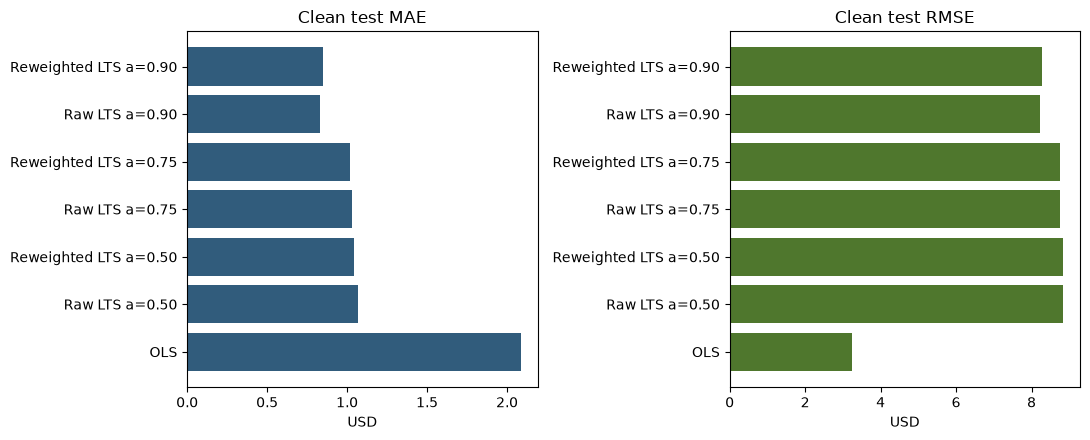

In [3]:
performance = pd.read_csv(TABLES / "clean_model_performance.csv")
test_performance = performance.loc[performance["evaluation_split"].eq("test")].copy()
display(test_performance.style.format({
    "alpha": lambda value: "" if pd.isna(value) else f"{value:.2f}",
    "mae": "{:.3f}", "rmse": "{:.3f}",
    "median_absolute_error": "{:.3f}", "r_squared": "{:.3f}",
}))

test_performance["label"] = test_performance.apply(
    lambda row: row["estimator"] if pd.isna(row["alpha"])
    else f"{row['estimator']} a={row['alpha']:.2f}", axis=1,
)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].barh(test_performance["label"], test_performance["mae"], color="#315C7C")
axes[0].set(title="Clean test MAE", xlabel="USD")
axes[1].barh(test_performance["label"], test_performance["rmse"], color="#4F772D")
axes[1].set(title="Clean test RMSE", xlabel="USD")
plt.tight_layout()
plt.show()

In [4]:
coefficients = pd.read_csv(TABLES / "clean_model_coefficients.csv")
primary = coefficients.loc[
    coefficients["estimator"].eq("OLS") | coefficients["alpha"].eq(0.75)
]
display(primary.style.format({
    "alpha": lambda value: "" if pd.isna(value) else f"{value:.2f}",
    "coefficient_original_units": "{:.4f}",
    "ols_hc3_standard_error": lambda value: "" if pd.isna(value) else f"{value:.4f}",
}))

,estimator,alpha,term,coefficient_original_units,ols_hc3_standard_error
0,OLS,,const,5.2406,0.2853
1,OLS,,trip_distance,3.6218,0.0958
2,OLS,,duration_min,0.0824,0.0392
3,OLS,,passenger_count,0.1380,0.0360
4,OLS,,pickup_hour_sin,-0.5781,0.0611
5,OLS,,pickup_hour_cos,-1.0891,0.0876
6,OLS,,is_weekend,-0.7448,0.0653
21,Raw LTS,0.75,const,2.4559,
22,Raw LTS,0.75,trip_distance,1.7946,
23,Raw LTS,0.75,duration_min,0.6042,


In [5]:
display(test_performance[[
    "estimator", "alpha", "mae", "rmse", "median_absolute_error", "r_squared"
]].style.format(precision=3))

,estimator,alpha,mae,rmse,median_absolute_error,r_squared
7,OLS,nan,2.086,3.253,1.594,0.923
8,Raw LTS,0.500,1.069,8.842,0.344,0.434
9,Reweighted LTS,0.500,1.043,8.825,0.343,0.437
10,Raw LTS,0.750,1.030,8.756,0.344,0.445
11,Reweighted LTS,0.750,1.015,8.756,0.347,0.445
12,Raw LTS,0.900,0.833,8.227,0.370,0.510
13,Reweighted LTS,0.900,0.848,8.280,0.366,0.504


In [6]:
audit_summary = pd.read_csv(TABLES / "lts_audit_candidate_summary.csv")
candidates = pd.read_csv(TABLES / "lts_audit_candidates.csv")
display(audit_summary.style.format(precision=4))
display(candidates.head(15).style.format(precision=3))

,training_observations,alpha,raw_h_subset_size,raw_mad_scale,reweighting_cutoff,zero_reweight_count,absolute_standardized_residual_above_2_5_count,audit_candidate_count,audit_candidate_fraction
0,40000,0.7500,30000,0.5106,2.2414,6452,5929,6452,0.1613


,modeling_row_id,source_row_id,pickup_datetime,dropoff_datetime,fare_amount,trip_distance,duration_min,passenger_count,pickup_hour_sin,pickup_hour_cos,is_weekend,raw_lts_residual,raw_lts_standardized_robust_residual,zero_reweight_flag,absolute_standardized_residual_above_2_5,audit_candidate,absolute_standardized_residual
0,39938,2429744,2026-01-29 20:15:53,2026-01-30 20:12:56,7.900,1.230,1437.050,1.000,-0.866,0.500,0,-864.920,-1693.910,True,True,True,1693.910
1,21045,660951,2026-01-09 11:37:04,2026-01-10 11:33:26,7.200,0.520,1436.367,1.000,0.259,-0.966,0,-864.026,-1692.160,True,True,True,1692.160
2,41197,251108,2026-01-04 12:59:26,2026-01-05 12:31:33,8.600,1.410,1412.117,5.000,0.000,-1.000,1,-849.587,-1663.880,True,True,True,1663.880
3,48214,433589,2026-01-06 19:08:34,2026-01-07 18:42:25,24.000,4.400,1413.850,2.000,-0.966,0.259,0,-840.501,-1646.087,True,True,True,1646.087
4,41908,1419099,2026-01-17 11:42:37,2026-01-18 00:00:00,42.200,10.700,737.383,1.000,0.259,-0.966,1,-424.984,-832.314,True,True,True,832.314
5,27108,1349531,2026-01-16 15:28:20,2026-01-17 00:00:00,4.400,0.190,511.667,1.000,-0.707,-0.707,0,-307.504,-602.235,True,True,True,602.235
6,24930,347010,2026-01-05 18:26:19,2026-01-06 00:33:54,82.100,19.550,367.583,1.000,-1.000,-0.000,0,-177.469,-347.565,True,True,True,347.565
7,24189,1303821,2026-01-16 01:31:09,2026-01-16 04:37:43,5.800,0.610,186.567,1.000,0.259,0.966,0,-110.477,-216.365,True,True,True,216.365
8,29189,634991,2026-01-08 23:44:00,2026-01-09 00:40:17,156.300,43.500,56.283,1.000,-0.259,0.966,0,41.796,81.856,True,True,True,81.856
9,29993,589312,2026-01-08 15:02:40,2026-01-08 16:49:28,204.600,54.830,106.800,1.000,-0.707,-0.707,0,39.243,76.855,True,True,True,76.855
